# CourseCast: calibration warm-up
Train a simple classifier on a toy dataset, then check whether its probabilities can be trusted with a reliability diagram and the Brier score.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.calibration import calibration_curve, CalibrationDisplay
from sklearn.metrics import brier_score_loss

In [2]:
X, y = make_classification(n_samples=5000, n_features=20, n_informative=5,
                           n_redundant=5, flip_y=0.05, random_state=0)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42)

models = {"Logistic regression": LogisticRegression(max_iter=1000),
          "Gaussian naive Bayes": GaussianNB()}
probs = {}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    probs[name] = m.predict_proba(X_te)[:, 1]
    print(f"{name:22s} Brier = {brier_score_loss(y_te, probs[name]):.4f}")
print(f"{'Base rate (constant)':22s} Brier = {brier_score_loss(y_te, np.full(len(y_te), y_tr.mean())):.4f}")

Logistic regression    Brier = 0.0728
Gaussian naive Bayes   Brier = 0.1144
Base rate (constant)   Brier = 0.2501


Reliability diagram: bin predictions, then plot the mean predicted probability against the observed fraction of positives per bin. The diagonal is perfect calibration. Logistic regression is usually close to it; naive Bayes is typically overconfident (an S shape).

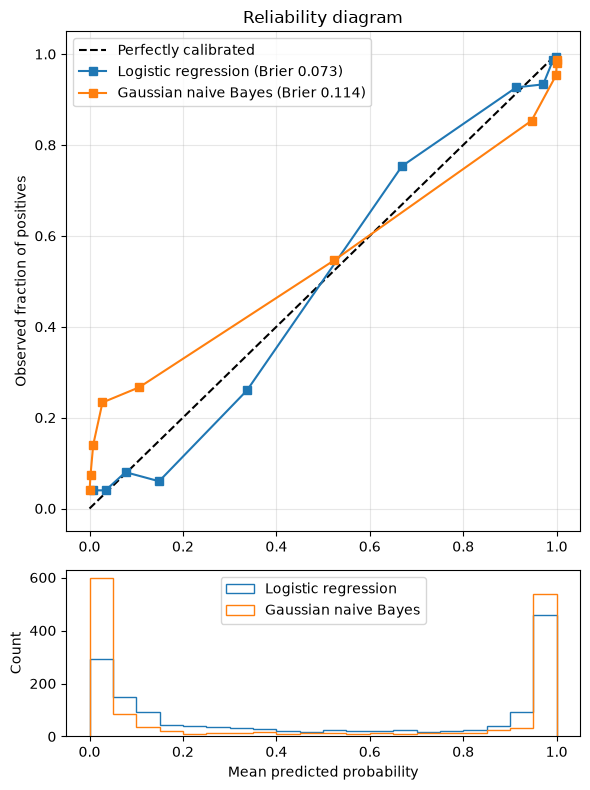

In [3]:
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(6, 8), gridspec_kw={"height_ratios": [3, 1]})
ax.plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")
for name, p in probs.items():
    frac_pos, mean_pred = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "s-", label=f"{name} (Brier {brier_score_loss(y_te, p):.3f})")
    ax2.hist(p, bins=20, range=(0, 1), histtype="step", label=name)
ax.set_ylabel("Observed fraction of positives"); ax.set_title("Reliability diagram")
ax.legend(loc="upper left"); ax.grid(alpha=.3)
ax2.set_xlabel("Mean predicted probability"); ax2.set_ylabel("Count"); ax2.legend()
plt.tight_layout(); plt.show()